In [2]:
import pandas as pd

# Đọc file dữ liệu
import os
data_path = 'data/raw/data.csv' if os.path.exists('data/raw/data.csv') else '../data/raw/data.csv'
df = pd.read_csv(data_path)

# Hiển thị toàn bộ các cột, không bị che bởi dấu ...
pd.set_option('display.max_columns', None)

# Danh sách 11 cột được dùng trên Web
columns_to_keep = [
    "Age at enrollment",
    "Gender",
    "Marital status",
    "Course",
    "Application order",
    "Previous qualification (grade)",
    "Admission grade",
    "Displaced",
    "Debtor",
    "Tuition fees up to date",
    "Scholarship holder"
]

df_11_cols = df[columns_to_keep]

# Hiển thị bảng siêu đẹp với đầy đủ 11 cột
df_11_cols.head()

,Age at enrollment,Gender,Marital status,Course,Application order,Previous qualification (grade),Admission grade,Displaced,Debtor,Tuition fees up to date,Scholarship holder
0,20,1,1,171,5,122.0,127.3,1,0,1,0
1,19,1,1,9254,1,160.0,142.5,1,0,0,0
2,19,1,1,9070,5,122.0,124.8,1,0,0,0
3,20,0,1,9773,2,122.0,119.6,1,0,1,0
4,45,0,2,8014,1,100.0,141.5,0,0,1,0


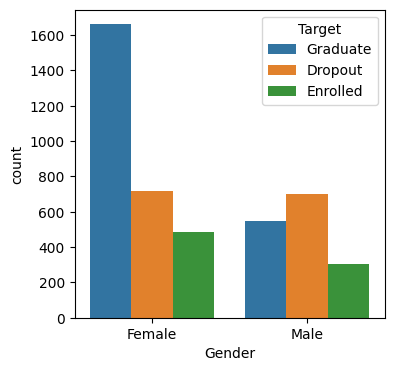

In [ ]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Đọc dữ liệu nếu chưa có
data_path = 'data/raw/data.csv' if os.path.exists('data/raw/data.c  sv') else '../data/raw/data.csv'
df = pd.read_csv(data_path)

# Vẽ biểu đồ
plt.figure(figsize=(4, 4))
sns.countplot(data=df, x='Gender', hue='Target')
plt.xticks(ticks=[0, 1], labels=['Female', 'Male'])
plt.show()

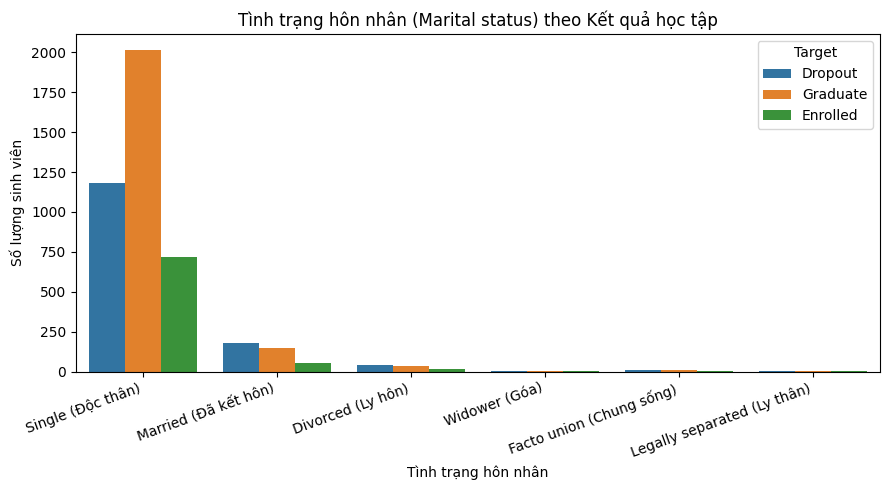

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Tạo cột nhãn rõ ràng để biểu đồ hiển thị chữ thay vì con số 1, 2, 3...
marital_map = {
    1: 'Single (Độc thân)',
    2: 'Married (Đã kết hôn)',
    3: 'Widower (Góa)',
    4: 'Divorced (Ly hôn)',
    5: 'Facto union (Chung sống)',
    6: 'Legally separated (Ly thân)'
}

df_plot = df.copy()
df_plot['Marital status label'] = df_plot['Marital status'].map(marital_map).fillna('Other')

plt.figure(figsize=(9, 5))
sns.countplot(
    data=df_plot,
    x='Marital status label',
    hue='Target',
    palette='tab10'
)
plt.title('Tình trạng hôn nhân (Marital status) theo Kết quả học tập')
plt.xlabel('Tình trạng hôn nhân')
plt.ylabel('Số lượng sinh viên')
plt.xticks(rotation=20, ha='right')
plt.legend(title='Target')
plt.tight_layout()
plt.show()

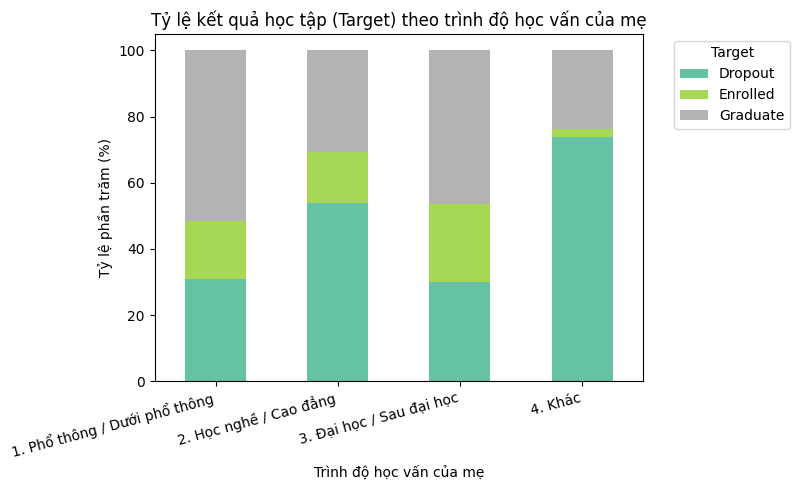

In [13]:
import matplotlib.pyplot as plt

# Biểu đồ tỷ lệ kết quả học tập theo trình độ của mẹ
norm_edu = pd.crosstab(df_analysis['Mothers_Edu_Group'], df_analysis['Target'], normalize='index') * 100

norm_edu.plot(kind='bar', stacked=True, figsize=(8, 5), colormap='Set2')
plt.title("Tỷ lệ kết quả học tập (Target) theo trình độ học vấn của mẹ")
plt.xlabel("Trình độ học vấn của mẹ")
plt.ylabel("Tỷ lệ phần trăm (%)")
plt.xticks(rotation=15, ha='right')
plt.legend(title='Target', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

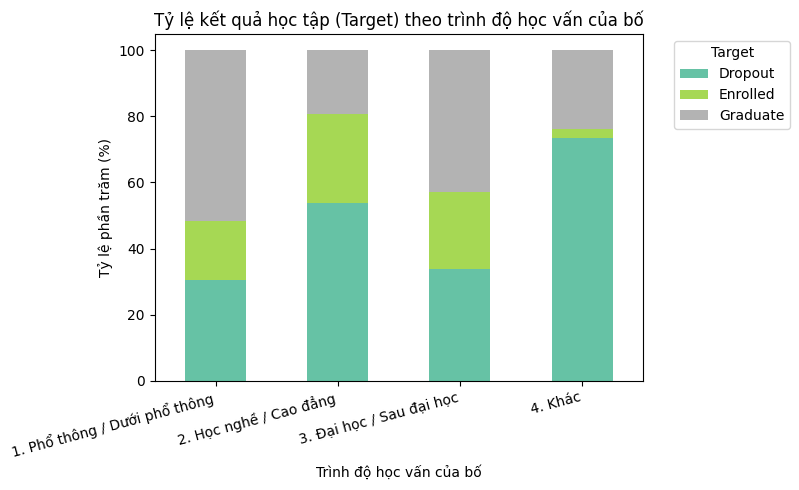

In [22]:
import matplotlib.pyplot as plt

# Tính tỷ lệ % theo từng nhóm học vấn của bố
norm_father_edu = pd.crosstab(df_analysis['Fathers_Edu_Group'], df_analysis['Target'], normalize='index') * 100

norm_father_edu.plot(kind='bar', stacked=True, figsize=(8, 5), colormap='Set2')
plt.title("Tỷ lệ kết quả học tập (Target) theo trình độ học vấn của bố")
plt.xlabel("Trình độ học vấn của bố")
plt.ylabel("Tỷ lệ phần trăm (%)")
plt.xticks(rotation=15, ha='right')
plt.legend(title='Target', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

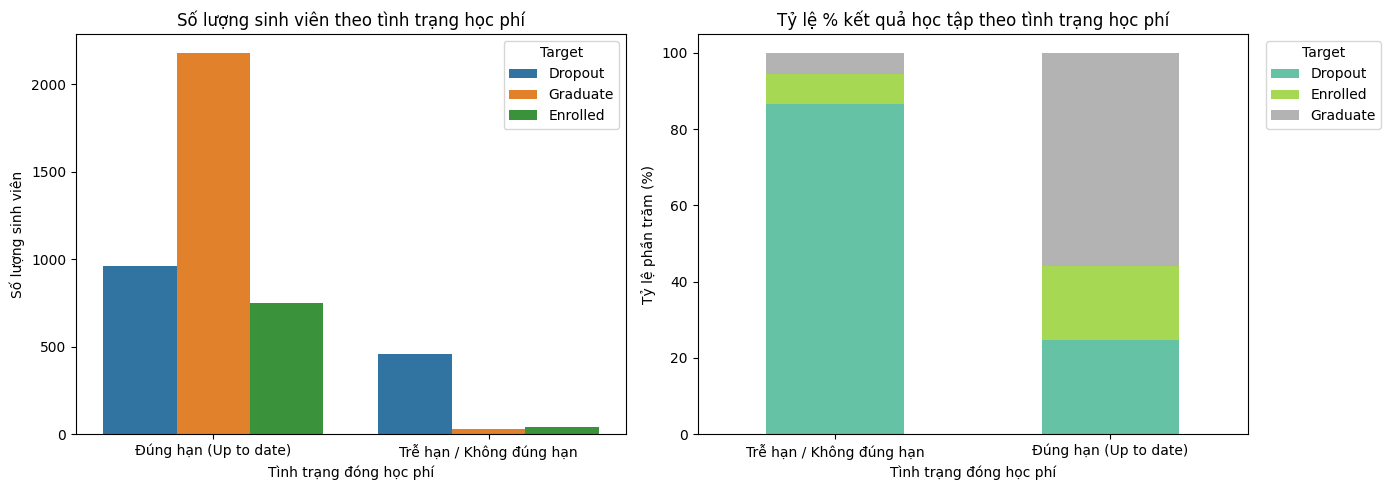

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ 1: Số lượng sinh viên (Countplot)
sns.countplot(
    data=df_plot,
    x='Tuition_Status',
    hue='Target',
    palette='tab10',
    ax=axes[0]
)
axes[0].set_title('Số lượng sinh viên theo tình trạng học phí')
axes[0].set_xlabel('Tình trạng đóng học phí')
axes[0].set_ylabel('Số lượng sinh viên')

# Biểu đồ 2: Tỷ lệ phần trăm (Stacked Bar 100%)
cross_tuition = pd.crosstab(df_plot['Tuition_Status'], df_plot['Target'], normalize='index') * 100
cross_tuition.plot(kind='bar', stacked=True, colormap='Set2', ax=axes[1])
axes[1].set_title('Tỷ lệ % kết quả học tập theo tình trạng học phí')
axes[1].set_xlabel('Tình trạng đóng học phí')
axes[1].set_ylabel('Tỷ lệ phần trăm (%)')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Target', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

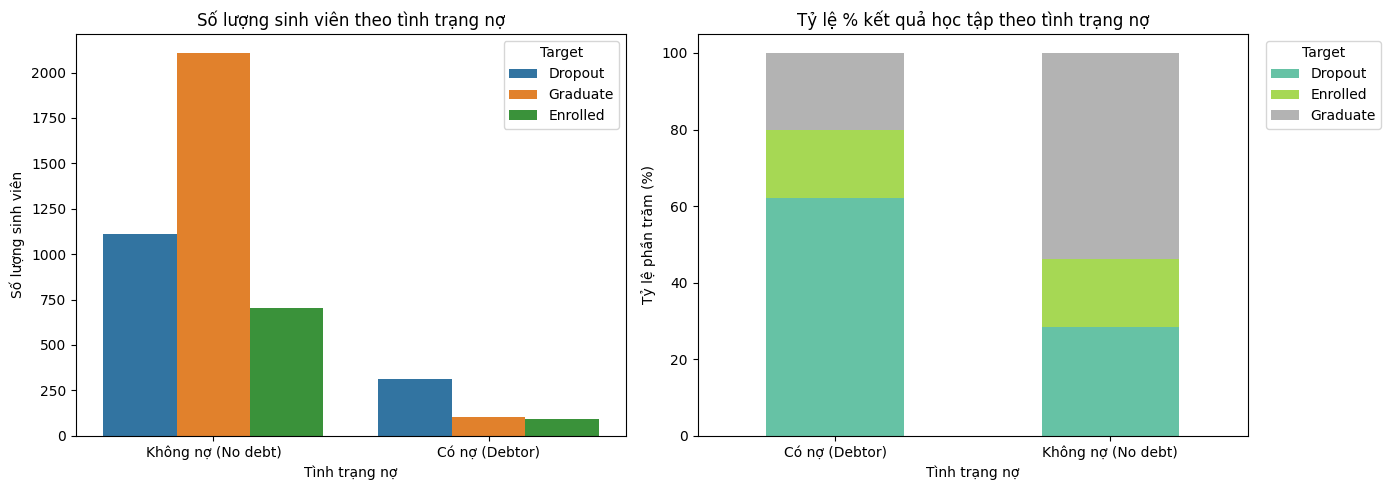

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ 1: Số lượng sinh viên (Countplot)
sns.countplot(
    data=df_plot,
    x='Debtor_Label',
    hue='Target',
    palette='tab10',
    ax=axes[0]
)
axes[0].set_title('Số lượng sinh viên theo tình trạng nợ')
axes[0].set_xlabel('Tình trạng nợ')
axes[0].set_ylabel('Số lượng sinh viên')

# Biểu đồ 2: Tỷ lệ phần trăm (100% Stacked Bar)
cross_debtor = pd.crosstab(df_plot['Debtor_Label'], df_plot['Target'], normalize='index') * 100
cross_debtor.plot(kind='bar', stacked=True, colormap='Set2', ax=axes[1])
axes[1].set_title('Tỷ lệ % kết quả học tập theo tình trạng nợ')
axes[1].set_xlabel('Tình trạng nợ')
axes[1].set_ylabel('Tỷ lệ phần trăm (%)')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Target', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

In [37]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Import bộ lọc loại bỏ biến tương lai từ src của project
from src.features import DropFutureFeatures

# Đọc dữ liệu
data_path = 'data/raw/data.csv' if os.path.exists('data/raw/data.csv') else '../data/raw/data.csv'
df = pd.read_csv(data_path)

# QUAN TRỌNG: Loại bỏ các biến học kỳ tương lai để không bị rò rỉ dữ liệu
dropper = DropFutureFeatures()
df_clean = dropper.fit_transform(df)

# Hàm đánh giá
def evaluate_two_models(X_train, X_test, y_train, y_test, is_binary=False):
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    models = {
        'Logistic Regression': (LogisticRegression(max_iter=3000, class_weight='balanced', random_state=42), True),
        'Random Forest': (RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42), False)
    }
    
    rows = []
    for name, (model, need_scale) in models.items():
        X_tr = X_train_scaled if need_scale else X_train
        X_te = X_test_scaled if need_scale else X_test
        model.fit(X_tr, y_train)
        pred = model.predict(X_te)
        
        if is_binary:
            prec = precision_score(y_test, pred, pos_label='Dropout', zero_division=0)
            rec = recall_score(y_test, pred, pos_label='Dropout', zero_division=0)
            f1 = f1_score(y_test, pred, pos_label='Dropout', zero_division=0)
        else:
            prec = precision_score(y_test, pred, average='macro', zero_division=0)
            rec = recall_score(y_test, pred, average='macro', zero_division=0)
            f1 = f1_score(y_test, pred, average='macro', zero_division=0)
            
        rows.append({
            'Model': name,
            'Accuracy': round(accuracy_score(y_test, pred), 3),
            'Precision': round(prec, 2),
            'Recall': round(rec, 2),
            'F1-score': round(f1, 2)
        })
    return pd.DataFrame(rows)

# 1. Với 3 lớp ban đầu (chuẩn không bị leak)
X_3 = df_clean.drop(columns=['Target'])
y_3 = df_clean['Target']
X_tr3, X_te3, y_tr3, y_te3 = train_test_split(X_3, y_3, test_size=0.2, random_state=42, stratify=y_3)
print("Với 3 lớp ban đầu dựa trên chỉ số F1-score (Đã loại Data Leakage):")
display(evaluate_two_models(X_tr3, X_te3, y_tr3, y_te3, is_binary=False))

# 2. Với nhị phân (chuẩn không bị leak)
df_bin = df_clean[df_clean['Target'].isin(['Dropout', 'Graduate'])].copy()
X_b = df_bin.drop(columns=['Target'])
y_b = df_bin['Target']
X_trb, X_teb, y_trb, y_teb = train_test_split(X_b, y_b, test_size=0.2, random_state=42, stratify=y_b)
print("Khi chuyển về lớp nhị phân dựa trên chỉ số Recall (Đã loại Data Leakage):")
display(evaluate_two_models(X_trb, X_teb, y_trb, y_teb, is_binary=True))

Với 3 lớp ban đầu dựa trên chỉ số F1-score (Đã loại Data Leakage):


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.529,0.53,0.51,0.50
1,Random Forest,0.605,0.55,0.54,0.54


Khi chuyển về lớp nhị phân dựa trên chỉ số Recall (Đã loại Data Leakage):


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.764,0.69,0.71,0.70
1,Random Forest,0.760,0.70,0.68,0.69


In [38]:
import joblib
import pandas as pd

# Load model đã huấn luyện
pipe = joblib.load('models/dropout_model.pkl' if os.path.exists('models/dropout_model.pkl') else '../models/dropout_model.pkl')
rf = pipe.named_steps['classifier']
prep = pipe.named_steps['preprocessor']

# Lấy top 10 đặc trưng quan trọng nhất
df_feat = pd.DataFrame({
    'Đặc trưng': prep.get_feature_names_out(),
    'Độ quan trọng': rf.feature_importances_
}).sort_values('Độ quan trọng', ascending=False)

display(df_feat.head(10))

,Đặc trưng,Độ quan trọng
1,num__Admission grade,0.065718
0,num__Previous qualification (grade),0.059535
2,num__Age at enrollment,0.056206
5,num__GDP,0.040777
3,num__Unemployment rate,0.037508
4,num__Inflation rate,0.036743
216,cat__Tuition fees up to date_1,0.033175
215,cat__Tuition fees up to date_0,0.030046
220,cat__Scholarship holder_1,0.019051
219,cat__Scholarship holder_0,0.016679


In [36]:
X_3 = df.drop(columns=['Target'])
y_3 = df['Target']
X_tr3, X_te3, y_tr3, y_te3 = train_test_split(X_3, y_3, test_size=0.2, random_state=42, stratify=y_3)

print("Với 3 lớp ban đầu dựa trên chỉ số F1-score:")
df_3class = evaluate_two_models(X_tr3, X_te3, y_tr3, y_te3, is_binary=False)
display(df_3class)
# Lọc chỉ lấy 2 lớp: Dropout và Graduate (bỏ Enrolled)
df_bin = df[df['Target'].isin(['Dropout', 'Graduate'])].copy()
X_b = df_bin.drop(columns=['Target'])
y_b = df_bin['Target']
X_trb, X_teb, y_trb, y_teb = train_test_split(X_b, y_b, test_size=0.2, random_state=42, stratify=y_b)

print("Khi chuyển về lớp nhị phân (Drop out, Graduate) dựa trên chỉ số Recall:")
df_binary = evaluate_two_models(X_trb, X_teb, y_trb, y_teb, is_binary=True)
display(df_binary)

Với 3 lớp ban đầu dựa trên chỉ số F1-score:


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.729,0.70,0.7,0.69
1,Random Forest,0.753,0.71,0.7,0.70


Khi chuyển về lớp nhị phân (Drop out, Graduate) dựa trên chỉ số Recall:


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.904,0.89,0.86,0.87
1,Random Forest,0.906,0.92,0.83,0.87


In [3]:
# Bảng liệt kê thông tin các cột, kiểu dữ liệu, số lượng null
df_11_cols.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 11 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Age at enrollment               4424 non-null   int64  
 1   Gender                          4424 non-null   int64  
 2   Marital status                  4424 non-null   int64  
 3   Course                          4424 non-null   int64  
 4   Application order               4424 non-null   int64  
 5   Previous qualification (grade)  4424 non-null   float64
 6   Admission grade                 4424 non-null   float64
 7   Displaced                       4424 non-null   int64  
 8   Debtor                          4424 non-null   int64  
 9   Tuition fees up to date         4424 non-null   int64  
 10  Scholarship holder              4424 non-null   int64  
dtypes: float64(2), int64(9)
memory usage: 380.3 KB
